In [1]:
!apt-get install python3-tk
!apt-get install python-opencv
!pip install captum

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
python3-tk is already the newest version (3.10.8-1~22.04).
0 upgraded, 0 newly installed, 0 to remove and 49 not upgraded.
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
E: Unable to locate package python-opencv
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 20.4 MB/s eta 0:00:00


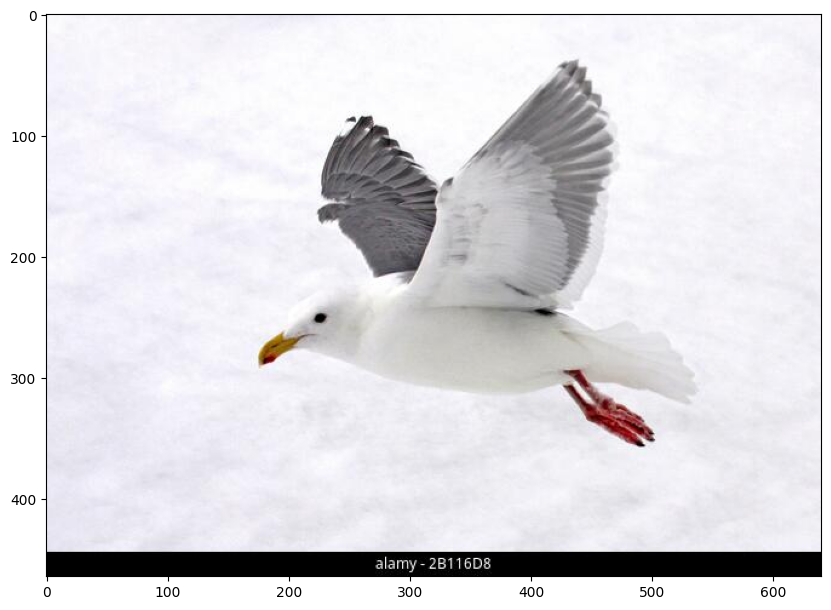

No regions selected for analysis!


In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, clear_output
import ipywidgets as widgets
from google.colab import drive
from google.colab.patches import cv2_imshow
import os

class DarknessAnalyzer:
    def __init__(self):
        self.regions = []
        self.current_image = None
        self.drawing = False
        self.ix, self.iy = -1, -1
        self.selected_regions = []
        self.temp_rectangle = None

    def draw_with_matplotlib(self, img_path):
        """Interactive region selection using matplotlib"""
        self.original_image = cv2.imread(img_path)
        self.original_image = cv2.cvtColor(self.original_image, cv2.COLOR_BGR2RGB)
        self.current_image = self.original_image.copy()
        self.gray_image = cv2.cvtColor(self.original_image, cv2.COLOR_RGB2GRAY)

        self.fig, self.ax = plt.subplots(figsize=(10, 10))
        self.ax.imshow(self.current_image)

        # Connect matplotlib events
        self.press = self.fig.canvas.mpl_connect('button_press_event', self.on_press)
        self.release = self.fig.canvas.mpl_connect('button_release_event', self.on_release)
        self.motion = self.fig.canvas.mpl_connect('motion_notify_event', self.on_motion)

        # Add control buttons
        analyze_button = widgets.Button(description='Analyze Regions')
        reset_button = widgets.Button(description='Reset Selections')

        analyze_button.on_click(self.analyze_button_clicked)
        reset_button.on_click(self.reset_button_clicked)

        display(widgets.HBox([analyze_button, reset_button]))
        plt.show()

    def on_press(self, event):
        if event.inaxes != self.ax:
            return
        self.drawing = True
        self.ix, self.iy = event.xdata, event.ydata

    def on_motion(self, event):
        if not self.drawing or event.inaxes != self.ax:
            return
        if self.temp_rectangle:
            self.temp_rectangle.remove()
        self.temp_rectangle = plt.Rectangle(
            (self.ix, self.iy),
            event.xdata - self.ix,
            event.ydata - self.iy,
            fill=False, color='red'
        )
        self.ax.add_patch(self.temp_rectangle)
        self.fig.canvas.draw_idle()

    def on_release(self, event):
        if not self.drawing or event.inaxes != self.ax:
            return
        self.drawing = False
        if self.temp_rectangle:
            self.temp_rectangle.remove()

        x1, y1 = int(min(self.ix, event.xdata)), int(min(self.iy, event.ydata))
        x2, y2 = int(max(self.ix, event.xdata)), int(max(self.iy, event.ydata))

        # Add permanent rectangle
        rect = plt.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False, color='green'
        )
        self.ax.add_patch(rect)
        self.selected_regions.append((x1, y1, x2, y2))
        self.fig.canvas.draw_idle()

    def reset_button_clicked(self, b):
        self.ax.clear()
        self.ax.imshow(self.original_image)
        self.selected_regions = []
        self.fig.canvas.draw_idle()

    def analyze_button_clicked(self, b):
        results = self.analyze_regions()
        self.visualize_results(results)

    def analyze_regions(self):
        """Analyze darkness in selected regions"""
        results = []

        for i, (x1, y1, x2, y2) in enumerate(self.selected_regions):
            # Ensure coordinates are within image bounds
            x1, x2 = max(0, x1), min(self.gray_image.shape[1], x2)
            y1, y2 = max(0, y1), min(self.gray_image.shape[0], y2)

            # Extract region from grayscale image
            region = self.gray_image[y1:y2, x1:x2]

            # Calculate darkness metrics
            avg_intensity = np.mean(region)
            relative_darkness = 1 - (avg_intensity / 255.0)

            results.append({
                'region_id': i + 1,
                'relative_darkness': relative_darkness,
                'avg_intensity': avg_intensity,
                'bbox': (x1, y1, x2, y2)
            })

        return results

    def visualize_results(self, results):
        """Visualize analysis results"""
        if not results:
            print("No regions selected for analysis!")
            return

        plt.figure(figsize=(15, 5))

        # Original image with regions
        plt.subplot(1, 2, 1)
        plt.imshow(self.original_image)
        for result in results:
            x1, y1, x2, y2 = result['bbox']
            plt.gca().add_patch(plt.Rectangle((x1, y1),
                                            x2 - x1,
                                            y2 - y1,
                                            fill=False,
                                            color='red',
                                            linewidth=2))
            plt.text(x1, y1-5, f"Region {result['region_id']}\nDarkness: {result['relative_darkness']:.2f}",
                    color='red', fontsize=10)
        plt.title("Selected Regions with Darkness Scores")
        plt.axis('off')

        # Darkness comparison bar plot
        plt.subplot(1, 2, 2)
        region_nums = [r['region_id'] for r in results]
        darkness_scores = [r['relative_darkness'] for r in results]
        plt.bar(region_nums, darkness_scores)
        plt.title("Relative Darkness by Region")
        plt.xlabel("Region Number")
        plt.ylabel("Darkness Score (0=white, 1=black)")

        plt.tight_layout()
        plt.show()

        # Print detailed results
        print("\nRegion Analysis Results:")
        for result in results:
            print(f"\nRegion {result['region_id']}:")
            print(f"  Relative Darkness: {result['relative_darkness']:.3f}")
            print(f"  Average Intensity: {result['avg_intensity']:.3f}")
            x1, y1, x2, y2 = result['bbox']
            print(f"  Location: (x: {x1}-{x2}, y: {y1}-{y2})")

# Example usage - put this in a separate cell to run
def main():


    # Set your image path
    image_path = '/content/2b116d8.jpg'  # Update this path

    # Create analyzer instance
    analyzer = DarknessAnalyzer()

    # Start analysis
    analyzer.draw_with_matplotlib(image_path)

# Run the main function
if __name__ == "__main__":
    main()